# 01 — Combined Cohort Composition, Splits & Demographics

Audits source-dataset balance, HDF5 shard inventory, zero patient leakage across `train`/`val`/`test`, and harmonized age/sex demographics.

/tmp/ipykernel_632030/910069287.py:30: DtypeWarning: Columns (1: source_record_id, 4: sex, 7: raw_labels) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(DATA_DIR / "metadata.csv.gz")


Total records : 547,452 across 220,313 unique patients
HDF5 shards   : 22 (float16, compression=lzf)


Patient leakage across train/val/test: 0 (VERIFIED)


split,test,train,val,All
source_dataset,,,,
chapman_shaoxing,2934,23468,2934,29336
code15,7975,63801,7975,79751
georgia_ecg,877,7016,877,8770
mimic_iv_ecg,40216,335878,43347,419441
ptbxl,1024,8104,1026,10154
All,53026,438267,56159,547452


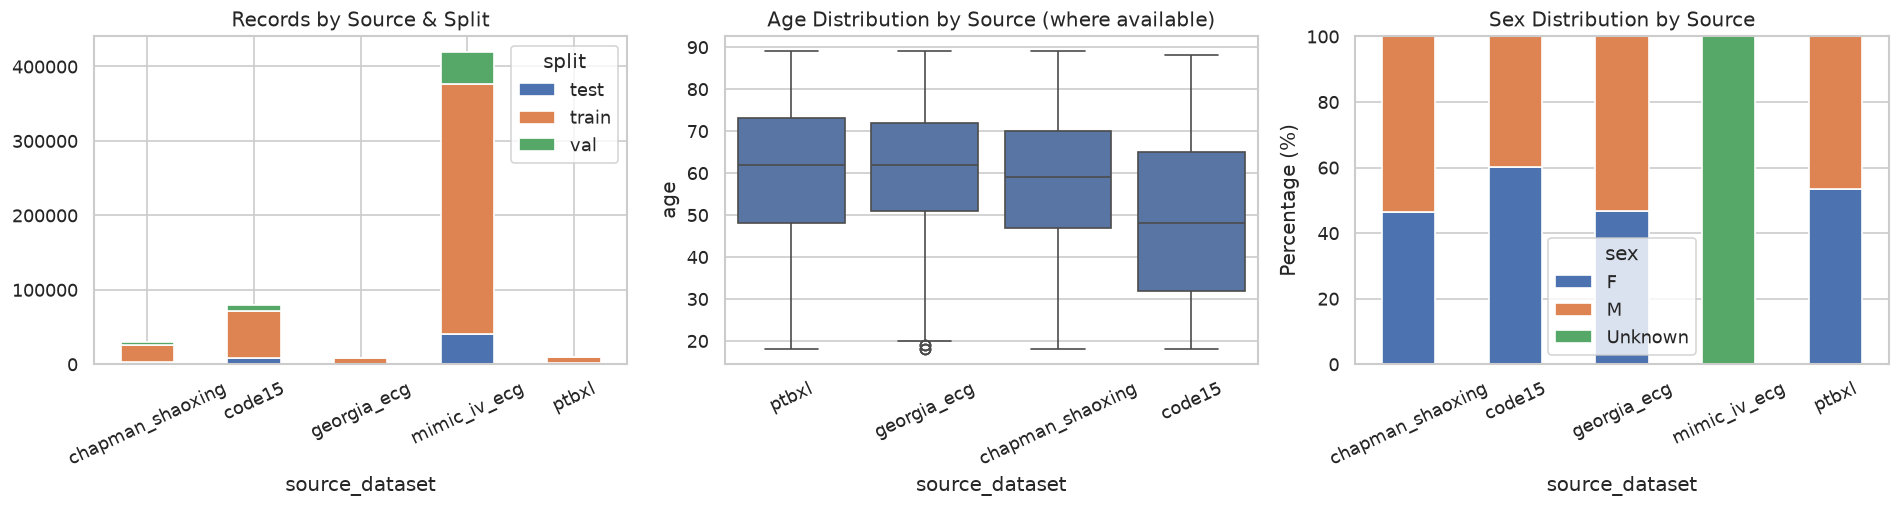

In [1]:
import json, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _cand in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_cand / "combined" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _cand
        break
else:
    raise FileNotFoundError(f"Could not locate combined/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from combined import CombinedECGDataset
COMBINED_DIR = REPO_ROOT / "combined"
DATA_DIR = COMBINED_DIR / "data"
QUALITY_DIR = COMBINED_DIR / "quality"
LEADS = CombinedECGDataset.LEADS

meta = pd.read_csv(DATA_DIR / "metadata.csv.gz")
cfg = json.loads((DATA_DIR / "build_config.json").read_text())

print(f"Total records : {len(meta):,} across {meta['patient_id'].nunique():,} unique patients")
print(f"HDF5 shards   : {cfg['n_shards']} ({cfg['storage_dtype']}, compression={cfg['compression']})")

# Patient leakage check
p_tr = set(meta.loc[meta["split"] == "train", "patient_id"])
p_va = set(meta.loc[meta["split"] == "val", "patient_id"])
p_te = set(meta.loc[meta["split"] == "test", "patient_id"])
assert p_tr.isdisjoint(p_va) and p_tr.isdisjoint(p_te) and p_va.isdisjoint(p_te), "Patient leakage detected!"
print("Patient leakage across train/val/test: 0 (VERIFIED)")

ct = pd.crosstab(meta["source_dataset"], meta["split"], margins=True)
display(ct)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
meta.groupby(["source_dataset", "split"]).size().unstack(fill_value=0).plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Records by Source & Split")
axes[0].tick_params(axis="x", rotation=25)

valid_age = meta.dropna(subset=["age"])
sns.boxplot(data=valid_age, x="source_dataset", y="age", ax=axes[1])
axes[1].set_title("Age Distribution by Source (where available)")
axes[1].tick_params(axis="x", rotation=25)

sex_ct = pd.crosstab(meta["source_dataset"], meta["sex"].fillna("Unknown").replace("", "Unknown"), normalize="index") * 100
sex_ct.plot(kind="bar", stacked=True, ax=axes[2])
axes[2].set_ylabel("Percentage (%)")
axes[2].set_title("Sex Distribution by Source")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()
